## Análisis exploratorio de Datos (EDA) - Dataset de Estrellas

El dataset **Astronomical Data** (Kaggle) contiene 240 estrellas clasificadas en 6 tipos, 40 de cada uno.

Para cada estrella se registraron las siguientes variables:

- **temperatura:** temperatura superficial (K)
- **luminosidad:** luminosidad relativa al Sol (L/Lo)
- **radio:** radio relativo al Sol (R/Ro)
- **magnitud_abs:** magnitud absoluta (menor valor = más brillante)
- **tipo_estrella:** código de 0 a 5 (0 Enana marrón, 1 Enana roja, 2 Enana blanca, 3 Secuencia principal, 4 Supergigante, 5 Hipergigante)
- **color** y **clase_espectral** (O, B, A, F, G, K, M)

**Objetivos:** describir cada variable, comparar los tipos de estrella y descubrir qué variables permiten distinguirlos mejor, usando nuevas visualizaciones.

![Image](img/Tipos_Estrellas.jpeg)

## 1.Librerías y carga de datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Cargar el Dataset
data = pd.read_csv("datos/cleaned_star_data.csv")
data

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,5,Blue,O
236,30839,834042.000000,1194.0000,-10.63,5,Blue,O
237,8829,537493.000000,1423.0000,-10.73,5,White,A
238,9235,404940.000000,1112.0000,-11.23,5,White,A


In [4]:
# Renombrar columnas para trabajar más fácil
data.columns = ["temperatura", "luminosidad", "radio", "magnitud_abs",
                "tipo_estrella", "color", "clase_espectral"]

# Nombre de cada tipo de estrella (según la documentación del dataset)
data["tipo"] = data["tipo_estrella"].map({0: "Enana marrón", 1: "Enana roja", 2: "Enana blanca",
                                          3: "Sec. principal", 4: "Supergigante", 5: "Hipergigante"})
orden_tipo = ["Enana marrón", "Enana roja", "Enana blanca", "Sec. principal", "Supergigante", "Hipergigante"]
data.head()

,temperatura,luminosidad,radio,magnitud_abs,tipo_estrella,color,clase_espectral,tipo
0,3068,0.002400,0.1700,16.12,0,Red,M,Enana marrón
1,3042,0.000500,0.1542,16.60,0,Red,M,Enana marrón
2,2600,0.000300,0.1020,18.70,0,Red,M,Enana marrón
3,2800,0.000200,0.1600,16.65,0,Red,M,Enana marrón
4,1939,0.000138,0.1030,20.06,0,Red,M,Enana marrón


## 2.Estructura y calidad de los datos

In [5]:
# Tipos de Datos, valores no nulos y memoria usada por el DataFrame
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   temperatura      240 non-null    int64  
 1   luminosidad      240 non-null    float64
 2   radio            240 non-null    float64
 3   magnitud_abs     240 non-null    float64
 4   tipo_estrella    240 non-null    int64  
 5   color            240 non-null    str    
 6   clase_espectral  240 non-null    str    
 7   tipo             240 non-null    str    
dtypes: float64(3), int64(2), str(3)
memory usage: 15.1 KB


In [6]:
# Valores faltantes y registros duplicados
print("Valores nulos por columna:")
print(data.isnull().sum())

print(f"\nRegistros duplicados: {data.duplicated().sum()}")

Valores nulos por columna:
temperatura        0
luminosidad        0
radio              0
magnitud_abs       0
tipo_estrella      0
color              0
clase_espectral    0
tipo               0
dtype: int64

Registros duplicados: 0


In [7]:
# Ver cuántos registros hay por tipo de estrella
data["tipo"].value_counts()

tipo
Enana marrón      40
Enana roja        40
Enana blanca      40
Sec. principal    40
Supergigante      40
Hipergigante      40
Name: count, dtype: int64

In [8]:
# Ver cuántos registros hay por clase espectral y por color
print(data["clase_espectral"].value_counts())
print()
print(data["color"].value_counts())

clase_espectral
M    111
B     46
O     40
A     19
F     17
K      6
G      1
Name: count, dtype: int64

color
Red             116
Blue             56
Blue-White       41
Yellow-White     15
White            12
Name: count, dtype: int64


In [9]:
# Número de valores únicos por columna del dataset
data.nunique()

temperatura        228
luminosidad        208
radio              216
magnitud_abs       228
tipo_estrella        6
color                5
clase_espectral      7
tipo                 6
dtype: int64

## 3. Estadísticas descriptivas

## 3.1 Estadísticas generales

In [10]:
# Muestra media, desviación estándar, mínimos, cuartiles (25%, 50% mediana, 75%) y máximo.
num_cols = ["temperatura", "luminosidad", "radio", "magnitud_abs"]
data[num_cols].describe()

,temperatura,luminosidad,radio,magnitud_abs
count,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396
std,9552.425037,179432.244940,517.155763,10.532512
min,1939.000000,0.000080,0.008400,-11.920000
25%,3344.250000,0.000865,0.102750,-6.232500
50%,5776.000000,0.070500,0.762500,8.313000
75%,15055.500000,198050.000000,42.750000,13.697500
max,40000.000000,849420.000000,1948.500000,20.060000


In [11]:
# Medidas adicionales: rango, rango intercuartílico (IQR), coeficiente de variación, asimetría y curtosis
num = data[num_cols]

resumen = pd.DataFrame({
    "media": num.mean(),
    "mediana": num.median(),
    "des_estandar": num.std(),
    "rango": num.max() - num.min(),
    "IQR": num.quantile(0.75) - num.quantile(0.25),
    "coeficiente_variacion": num.std() / num.mean() * 100,
    "asimetria": num.skew(),
    "curtosis": num.kurtosis()
})

resumen

,media,mediana,des_estandar,rango,IQR,coeficiente_variacion,asimetria,curtosis
temperatura,10497.462500,5776.0000,9552.425037,38061.00000,11711.250000,90.997468,1.321568,0.877352
luminosidad,107188.361635,0.0705,179432.244940,849419.99992,198049.999135,167.398999,2.068069,4.465098
radio,237.157781,0.7625,517.155763,1948.49160,42.647250,218.064008,1.946800,2.072935
magnitud_abs,4.382396,8.3130,10.532512,31.98000,19.930000,240.336856,-0.121540,-1.655888


## 3.2 Estadísticas por tipo de estrella

In [12]:
# Mediana de cada variable por tipo de estrella
data.groupby("tipo")[num_cols].median().reindex(orden_tipo).round(4)

,temperatura,luminosidad,radio,magnitud_abs
tipo,,,,
Enana marrón,2935.0,0.0005,0.1060,17.145
Enana roja,3314.0,0.0032,0.3380,12.605
Enana blanca,13380.0,0.0008,0.0102,12.340
Sec. principal,12560.5,738.5000,5.7125,-1.180
Supergigante,12821.0,242145.0000,43.5000,-6.235
Hipergigante,3766.0,266500.0000,1352.5000,-9.915


## 3.3 Variables derivadas (ingeniería de características)

In [13]:
# Nuevas variables a partir de las originales (logaritmo, porque varían en varios órdenes de magnitud)
data["log_luminosidad"] = np.log10(data["luminosidad"])
data["log_radio"] = np.log10(data["radio"])

der_cols = ["log_luminosidad", "log_radio"]
data.groupby("tipo")[der_cols].mean().reindex(orden_tipo).round(2)

,log_luminosidad,log_radio
tipo,,
Enana marrón,-3.31,-0.97
Enana roja,-2.55,-0.50
Enana blanca,-3.18,-1.97
Sec. principal,2.44,0.52
Supergigante,5.42,1.63
Hipergigante,5.41,3.13


El logaritmo reduce de forma notable la asimetría de `luminosidad` y `radio`, por lo que se usará en la correlación y en algunas gráficas.

## 4. Visualizaciones

## 4.1 Diagrama de cajas y bigotes

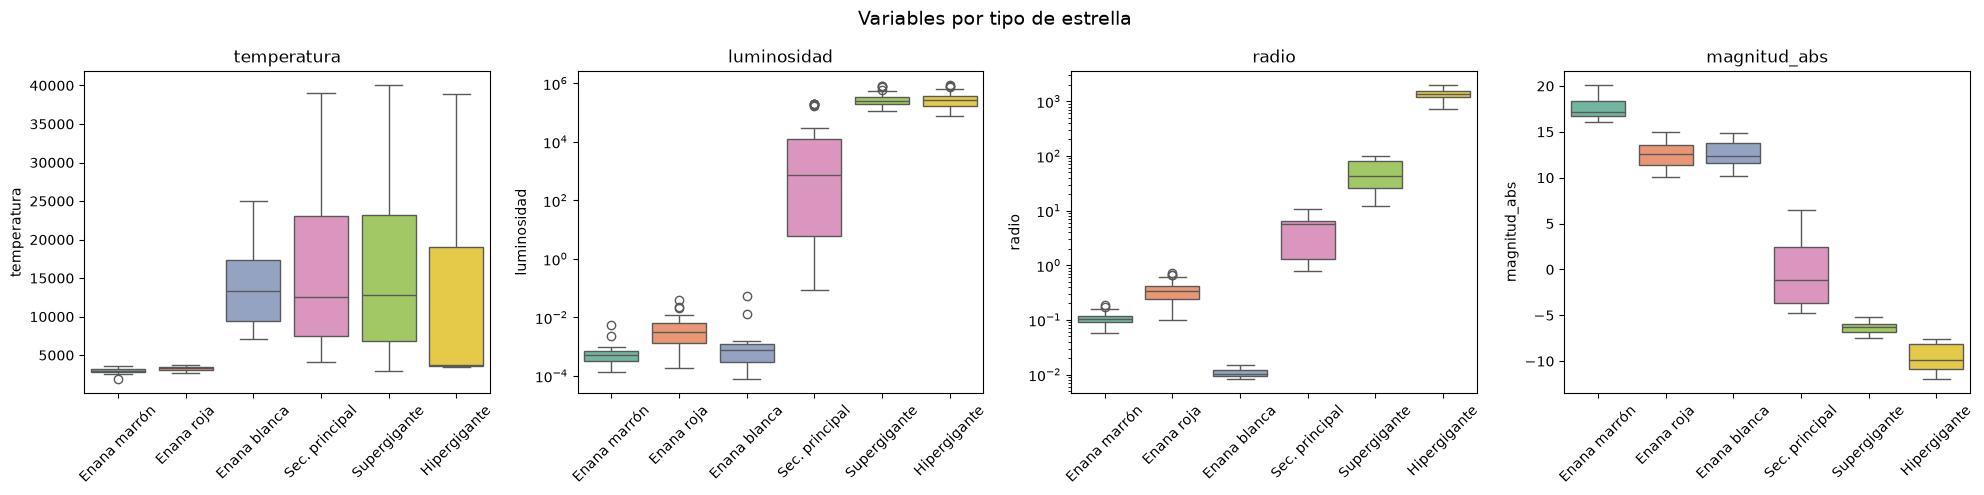

In [14]:
# Diagrama de cajas y bigotes
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=data, x="tipo", y=col, order=orden_tipo, hue="tipo", palette="Set2", legend=False, ax=ax)
    if col in ["luminosidad", "radio"]:
        ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Variables por tipo de estrella", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
# Cantidad de valores atípicos por variable (regla 1.5 x IQR)
for col in num_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n} atípicos")

temperatura: 11 atípicos
luminosidad: 12 atípicos
radio: 40 atípicos
magnitud_abs: 0 atípicos


**Interpretación:**
- `luminosidad` y `radio` (escala log): cada tipo se ubica en un nivel distinto, con poco solapamiento entre enanas y gigantes, por lo que son muy útiles para distinguir tipos. Los atípicos corresponden a estrellas gigantes, no a errores.
- `magnitud_abs`: su orden es inverso al de la luminosidad (valores más negativos = más brillante) y no presenta atípicos.
- `temperatura`: las cajas se solapan mucho entre tipos, por lo que sola no sirve para clasificar.

## 4.2 Histogramas con KDE

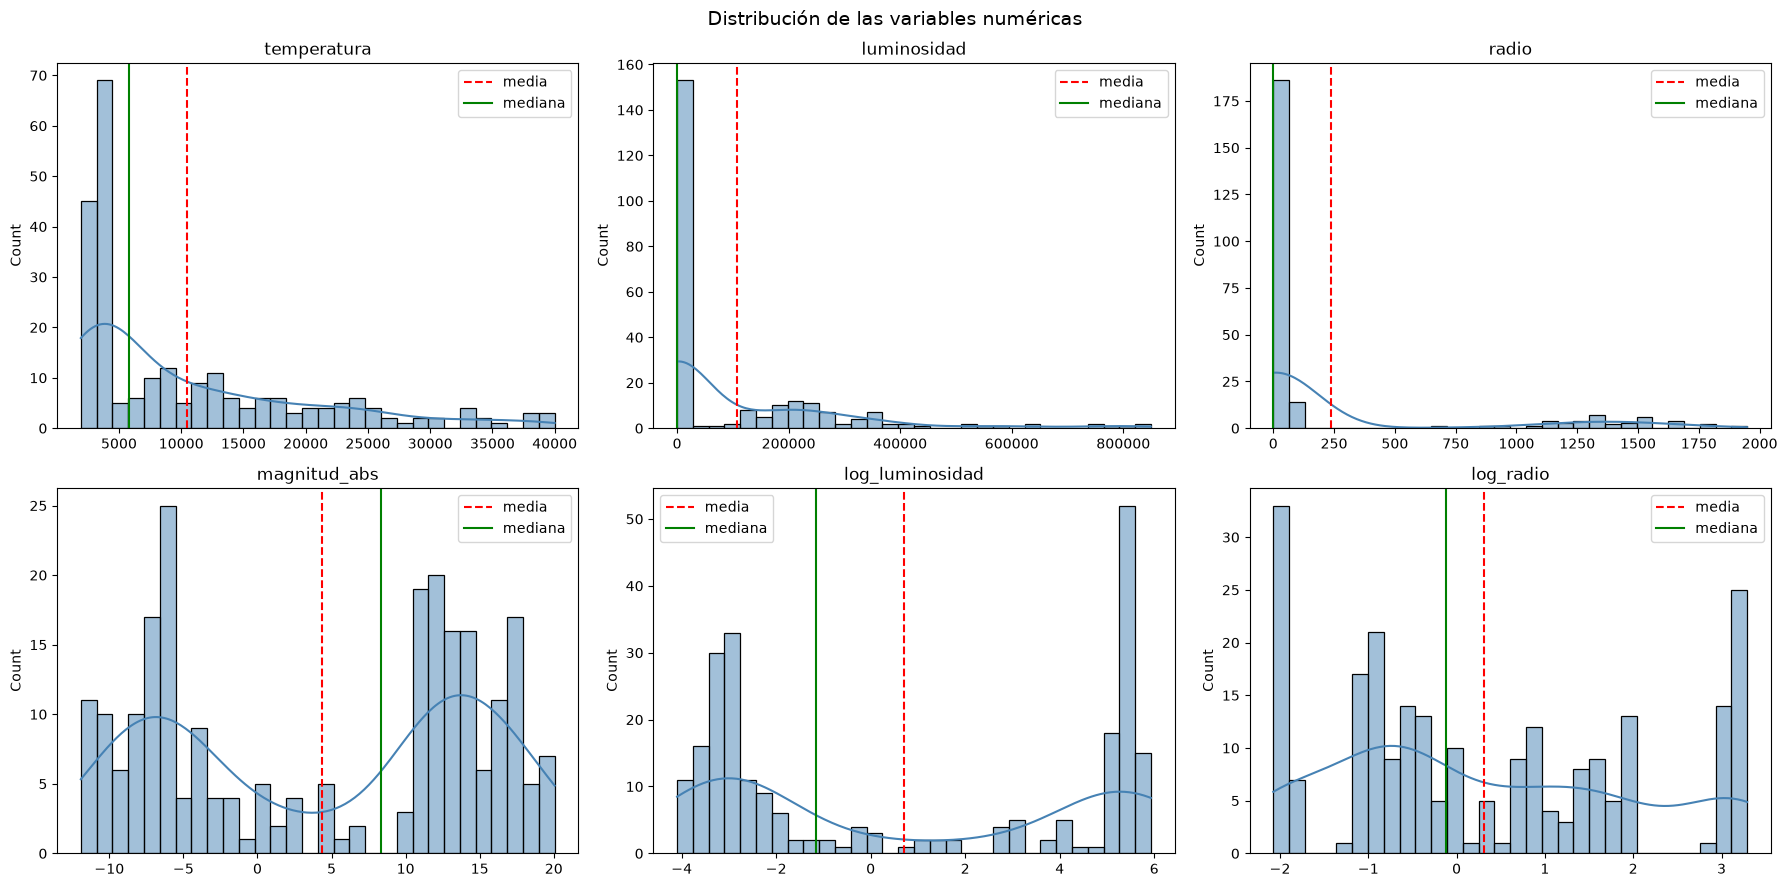

In [16]:
# Distribución de cada variable (original y con logaritmo)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
cols_hist = ["temperatura", "luminosidad", "radio", "magnitud_abs", "log_luminosidad", "log_radio"]

for ax, col in zip(axes.flat, cols_hist):
    sns.histplot(data[col], bins=30, kde=True, color="steelblue", ax=ax)
    ax.axvline(data[col].mean(), color="red", linestyle="--", label="media")
    ax.axvline(data[col].median(), color="green", label="mediana")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.legend()

plt.suptitle("Distribución de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:**
- `luminosidad` y `radio` están fuertemente sesgadas a la derecha: la mayoría de estrellas se concentra cerca de cero y pocas gigantes estiran la cola; la media queda lejos de la mediana.
- Con logaritmo las distribuciones se extienden y aparecen varios grupos, porque la muestra mezcla tipos muy distintos.
- `temperatura` es asimétrica a la derecha: la mayoría está por debajo de unos 15 000 K, con una cola hasta 40 000 K.
- `magnitud_abs` es la más equilibrada.

## 4.3 Mapa de calor de correlaciones

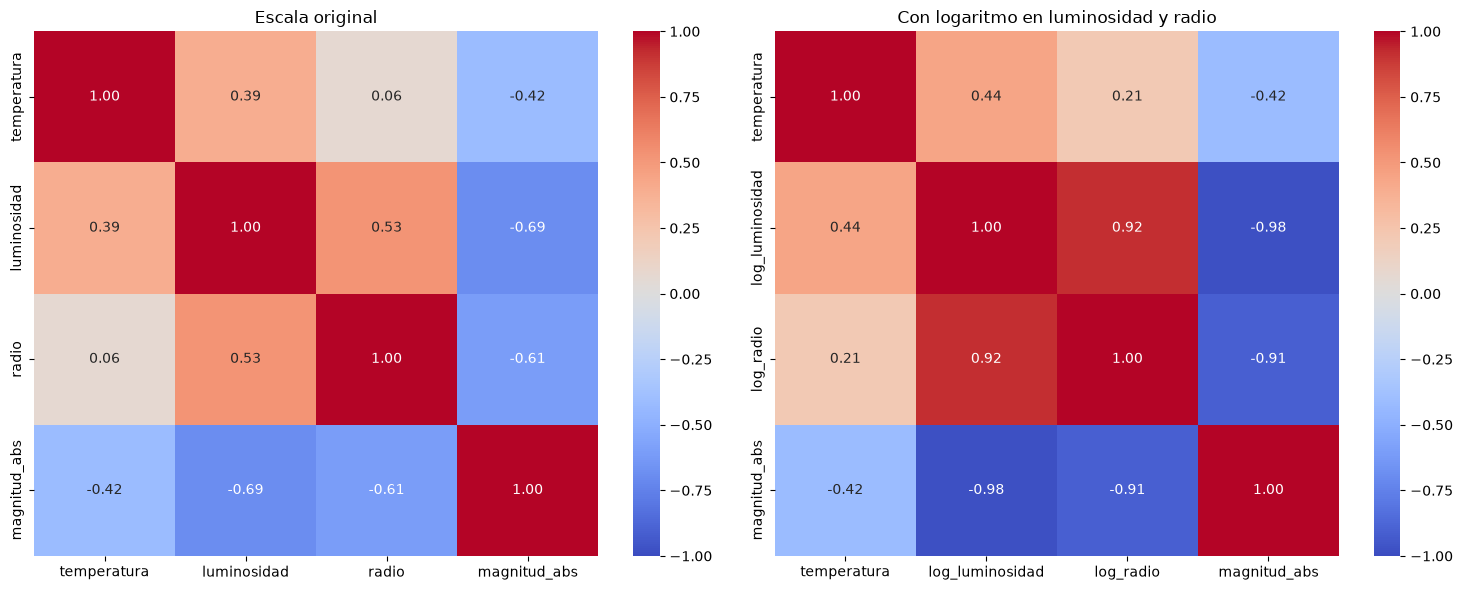

In [17]:
# Correlación con la escala original y con logaritmo
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(data[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", ax=axes[0])
axes[0].set_title("Escala original")

cols_log = ["temperatura", "log_luminosidad", "log_radio", "magnitud_abs"]
sns.heatmap(data[cols_log].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", ax=axes[1])
axes[1].set_title("Con logaritmo en luminosidad y radio")

plt.tight_layout()
plt.show()

**Interpretación:**
- En escala original las correlaciones parecen moderadas (luminosidad y magnitud ≈ -0,69) porque los valores extremos distorsionan la relación.
- Con logaritmo aparecen relaciones muy fuertes: `log_luminosidad` y `magnitud_abs` ≈ -0,98, y `log_luminosidad` y `log_radio` ≈ 0,92.
- `temperatura` tiene correlaciones bajas o moderadas con el resto (|r| ≤ 0,44), así que aporta información distinta.
- Correlación no implica causalidad; además, luminosidad y magnitud son casi la misma información en escalas distintas.

## 4.4 Diagrama de dispersión (tipo Hertzsprung-Russell)

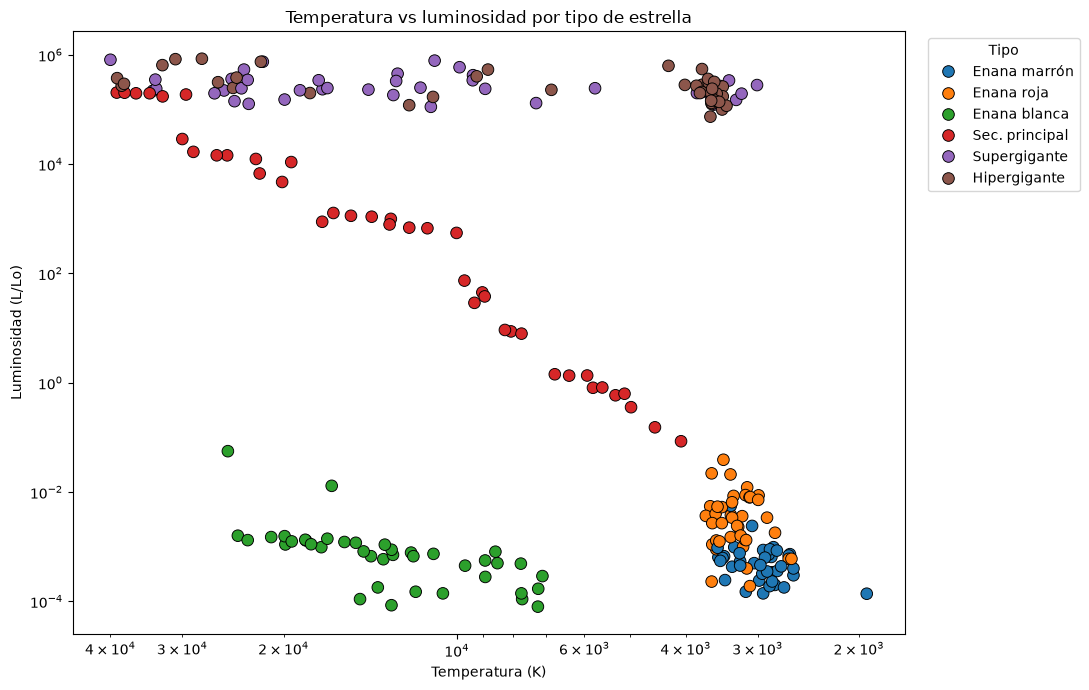

In [18]:
# Temperatura vs luminosidad, coloreado por tipo de estrella
plt.figure(figsize=(11, 7))
sns.scatterplot(data=data, x="temperatura", y="luminosidad", hue="tipo",
                hue_order=orden_tipo, palette="tab10", s=70, edgecolor="black")
plt.xscale("log")
plt.yscale("log")
plt.gca().invert_xaxis()   # convención astronómica: más caliente a la izquierda
plt.xlabel("Temperatura (K)")
plt.ylabel("Luminosidad (L/Lo)")
plt.title("Temperatura vs luminosidad por tipo de estrella")
plt.legend(title="Tipo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación:**
- Los tipos forman regiones separadas: enanas marrones y rojas (frías y poco luminosas) abajo a la derecha, enanas blancas (calientes y poco luminosas) abajo a la izquierda, la secuencia principal como una banda diagonal, y supergigantes e hipergigantes arriba.
- Combinar temperatura y luminosidad separa los tipos mucho mejor que cada variable por separado. Es el hallazgo central del análisis.
- Las hipergigantes incluyen estrellas frías y calientes, por eso se extienden horizontalmente en la parte superior.

## 4.5 Diagrama de violín

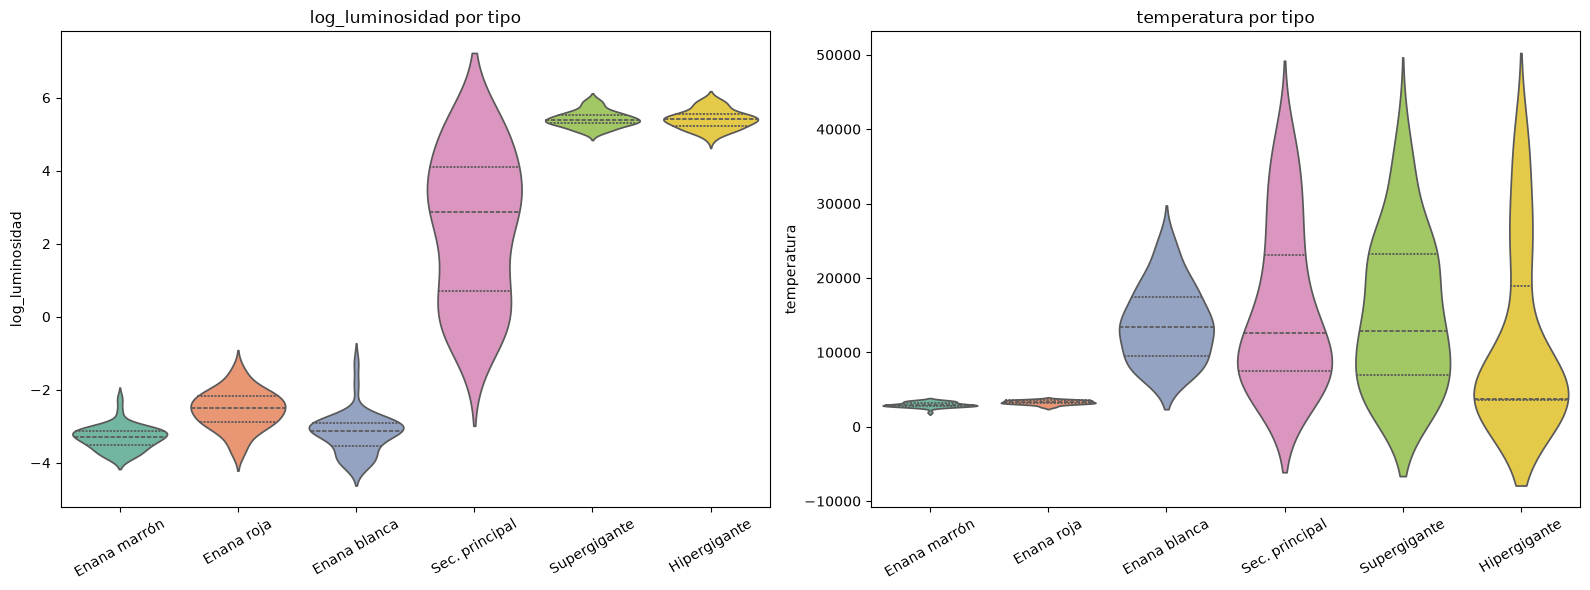

In [19]:
# Forma de la distribución por tipo de estrella
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.violinplot(data=data, x="tipo", y="log_luminosidad", order=orden_tipo, hue="tipo",
               palette="Set2", legend=False, inner="quartile", ax=axes[0])
axes[0].set_title("log_luminosidad por tipo")

sns.violinplot(data=data, x="tipo", y="temperatura", order=orden_tipo, hue="tipo",
               palette="Set2", legend=False, inner="quartile", ax=axes[1])
axes[1].set_title("temperatura por tipo")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Interpretación:** el violín muestra la forma de cada distribución, algo que el boxplot no muestra. En `log_luminosidad` cada tipo ocupa un rango propio con poca superposición; en `temperatura` varios tipos (enanas blancas, secuencia principal, supergigantes) tienen distribuciones anchas y traslapadas.

## 4.6 Conteos: clase espectral y color por tipo de estrella

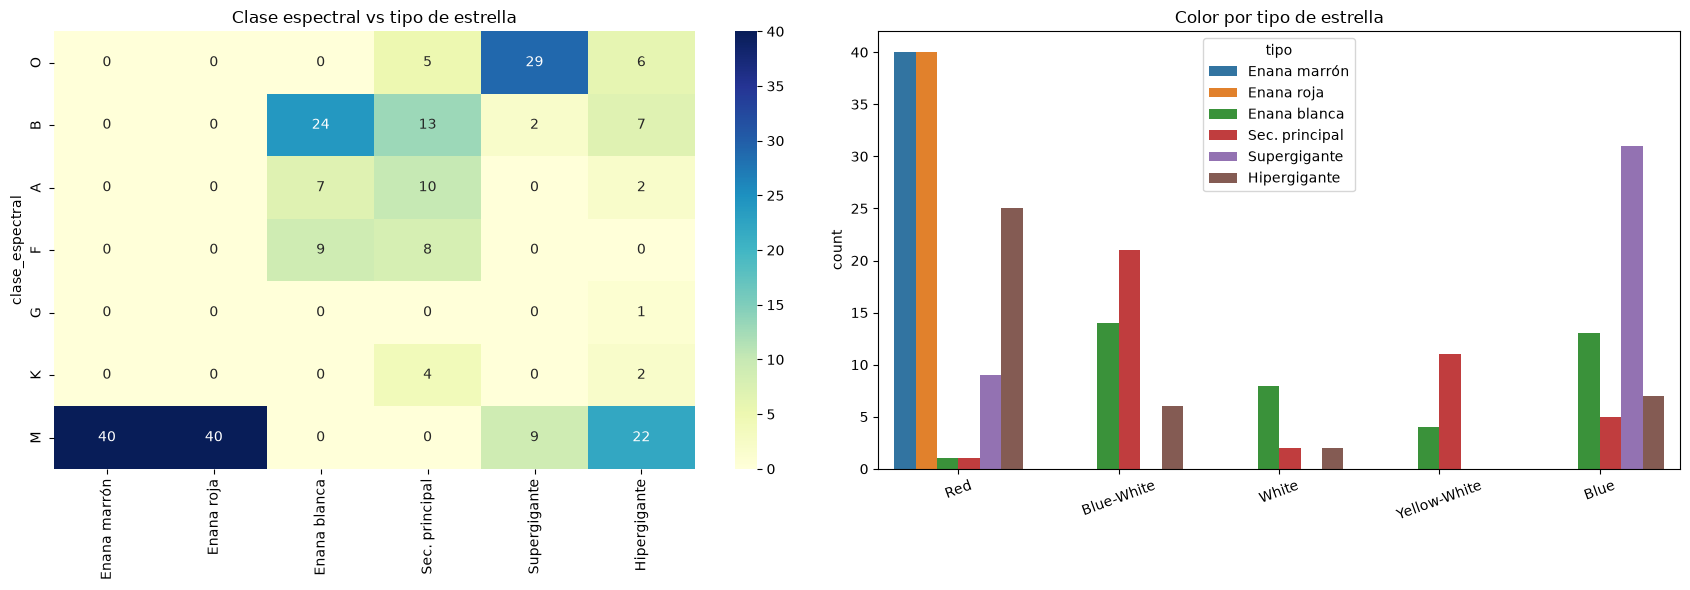

In [20]:
# Tabla de conteos (heatmap) y gráfico de barras
orden_clase = ["O", "B", "A", "F", "G", "K", "M"]   # de más caliente a más fría

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

tabla = pd.crosstab(data["clase_espectral"], data["tipo"]).reindex(orden_clase)[orden_tipo]
sns.heatmap(tabla, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Clase espectral vs tipo de estrella")
axes[0].set_xlabel("")

sns.countplot(data=data, x="color", hue="tipo", hue_order=orden_tipo, palette="tab10", ax=axes[1])
axes[1].set_title("Color por tipo de estrella")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [21]:
# Temperatura mediana por clase espectral
data.groupby("clase_espectral")["temperatura"].median().reindex(orden_clase)

clase_espectral
O    22369.0
B    18850.0
A     9030.0
F     7230.0
G     6850.0
K     4406.5
M     3324.0
Name: temperatura, dtype: float64

**Interpretación:**
- Las enanas marrones y rojas son 100 % clase M y de color rojo; las enanas blancas aparecen en las clases B, A y F; las supergigantes se concentran en la clase O.
- La temperatura mediana baja de forma consistente de O a M (22 369 K en O frente a 3 324 K en M), lo que confirma que la clase espectral indica temperatura.
- Solo hay una estrella de clase G, así que esa categoría no es representativa.

## 5. Conclusiones

1. El dataset está limpio (0 nulos y 0 duplicados), pero balanceado por diseño (40 estrellas por tipo), así que no sirve para estimar qué tan frecuente es cada tipo en la naturaleza.
2. `luminosidad` y `radio` varían en varios órdenes de magnitud y tienen fuerte asimetría; la escala logarítmica es necesaria para graficarlas y correlacionarlas bien.
3. Tras el logaritmo, luminosidad, radio y magnitud absoluta están fuertemente relacionadas (|r| entre 0,91 y 0,98); la temperatura aporta información distinta.
4. Luminosidad y radio distinguen bien los tipos. La temperatura sola se solapa mucho, pero combinada con la luminosidad separa los grupos con claridad.
5. La clase espectral y el color se asocian al tipo de estrella y ordenan la temperatura de forma coherente.
6. Limitaciones: muestra pequeña (240), balanceada artificialmente y con una sola estrella de clase G; el análisis es exploratorio, no inferencial.